# Home Credit Scorecard Model
### Notebook 02 — Modelling dataset and preprocessing (Section 11 and Step 4)

This notebook continues `01_research_data_eda.ipynb` (Steps 1–3) and **must run after it**, because it uses the saved
validation split (`data/processed/split_assignment.csv`). The work is split across notebooks so that each starts with a
fresh Python process: running the full pipeline in one kernel exceeded the available memory (about 4 GB).

Data: the eight files provided for this project (see notebook 01, Section 2).

In [1]:
import ctypes
import gc
import json
import os
import platform
import sys
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.metrics import roc_auc_score

SEED = 42
pd.set_option("display.max_columns", 50, "display.width", 200, "display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def find_project_root(start: Path) -> Path:
    """Project root = the folder containing src/build_dataset.py, searched upward from the notebook folder.
    Override with the HC_PROJECT_ROOT environment variable."""
    if os.environ.get("HC_PROJECT_ROOT"):
        return Path(os.environ["HC_PROJECT_ROOT"]).resolve()
    for folder in [start, *start.parents]:
        if (folder / "src" / "build_dataset.py").exists():
            return folder
    raise FileNotFoundError(
        f"Project root not found searching upward from {start}.\n"
        "Expected folder layout:\n"
        "  home-credit-scorecard-model/\n"
        "    notebooks/02_dataset_preprocessing.ipynb   <- this notebook\n"
        "    src/__init__.py, src/build_dataset.py, src/preprocessing.py\n"
        "    data/raw/   (the provided CSV files)\n"
        "Fix: unzip the complete project folder and open the notebook from its notebooks/ folder, "
        "or set HC_PROJECT_ROOT to the folder that contains src/.")


ROOT = find_project_root(Path.cwd().resolve())
for f in ["__init__.py", "build_dataset.py", "preprocessing.py"]:
    assert (ROOT / "src" / f).exists(), f"Missing {ROOT / 'src' / f} - copy the complete src/ folder"

# Package checks (clear messages instead of obscure errors later)
import re
_skl = tuple(int(x) for x in re.findall(r"\d+", sklearn.__version__)[:2])
assert _skl >= (1, 7), (
    f"scikit-learn {sklearn.__version__} found; 1.7 or newer is required. "
    "Run: pip install -U scikit-learn  (or: conda install -c conda-forge scikit-learn>=1.7)")
try:
    import pyarrow  # noqa: F401  (needed for the .parquet dataset files)
except ImportError as e:
    raise ImportError("pyarrow is required. Run: pip install pyarrow  (or: conda install -c conda-forge pyarrow)") from e

DATA_CANDIDATES = [os.environ.get("HC_DATA_DIR"), ROOT / "data" / "raw", Path("/mnt/user-data/uploads")]
DATA_DIR = next((Path(c) for c in DATA_CANDIDATES if c and (Path(c) / "application_train.csv").exists()), None)
assert DATA_DIR is not None, "application_train.csv not found - set HC_DATA_DIR or place files in data/raw"
REPORTS, FIG, PROCESSED = ROOT / "reports", ROOT / "reports" / "figures", ROOT / "data" / "processed"
assert (PROCESSED / "split_assignment.csv").exists(), "Run notebook 01 first: it creates the validation split"


def release_memory():
    # Free Python objects and hand unused heap memory back to the operating system
    gc.collect()
    try:
        ctypes.CDLL("libc.so.6").malloc_trim(0)
    except OSError:
        pass


print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__}")
print("Project root:", ROOT)
print("DATA_DIR:", DATA_DIR)

Python 3.12.3 | pandas 3.0.2 | numpy 2.4.4 | scikit-learn 1.8.0
Project root: /mnt/user-data/outputs/home-credit-scorecard-model
DATA_DIR: /mnt/user-data/uploads


## 11. Modelling dataset: one row per applicant

Preprocessing (Step 4) must be fitted on the final feature set, so the history tables are aggregated first.
`src/build_dataset.py` turns the eight provided tables into one row per `SK_ID_CURR`:
* rule-based cleaning: coded placeholders become missing, impossible dates become missing, and bureau records updated
  after the application are excluded;
* per-applicant aggregates of every history table, with `HAS_<TABLE>` flags for applicants without history.

It uses **no `TARGET` information and no statistics across applicants**, so it is safe to run before the data are split.
Every learned transformation happens later, inside the model pipelines. The engineered features are analysed in
detail in Step 5. The build runs in a separate process so that its memory is released afterwards.

In [2]:
import subprocess
import sys

# Run the build script by file path (independent of the current working directory); PYTHONPATH lets it
# import the project if needed. A separate process releases all of its memory when it finishes.
env = {**os.environ, "PYTHONPATH": str(ROOT) + os.pathsep + os.environ.get("PYTHONPATH", "")}
res = subprocess.run([sys.executable, str(ROOT / "src" / "build_dataset.py"), "--data-dir", str(DATA_DIR),
                      "--out", str(PROCESSED), "--split-file", str(PROCESSED / "split_assignment.csv")],
                     cwd=ROOT, env=env, capture_output=True, text=True)
if res.returncode != 0:
    print(res.stdout[-3000:])
    raise RuntimeError(f"Dataset build failed (exit code {res.returncode}):\n{res.stderr[-3000:]}")
print(next((l for l in res.stdout.splitlines() if "done:" in l), "build finished"))
build_report = json.loads((PROCESSED / "build_report.json").read_text())
display(pd.Series(build_report, name="value").to_frame())

[    95s] done: train (307511, 226), test (48744, 224), engineered 103


,value
app_train_rows,307511
app_test_rows,48744
coverage_pct_PREV,95.1
bureau_rows_excluded_updated_after_application,17
bureau_impossible_dates_set_missing,184
coverage_pct_BUREAU,85.84
coverage_pct_POS,94.67
coverage_pct_CC,29.07
installment_rows,13605401
instalments,12951918


In [3]:
ddict = pd.read_csv(PROCESSED / "data_dictionary.csv")
print(f"Engineered features documented: {len(ddict)}")
display(ddict.source.value_counts().to_frame("features"))
display(ddict.sample(8, random_state=SEED))

Engineered features documented: 103


,features
source,
bureau (records updated after application excluded),22
previous_application (final versions),21
application,15
credit_card_balance,12
installments_payments (payments summed per instalment first),12
POS_CASH_balance,11
bureau_balance (via bureau),5
previous_application,1
bureau,1


,feature,source,formula,meaning
30,PREV_APPR_CREDIT_TO_APP_MIN,previous_application (final versions),"min AMT_CREDIT / AMT_APPLICATION, approved",Largest past amount cut
67,POS_MAX_DPD,POS_CASH_balance,max SK_DPD,Worst POS/cash delinquency
62,BB_SHARE_MONTHS_DPD,bureau_balance (via bureau),months with DPD / months with known status,Frequency of external delinquency
47,BUR_MAX_DAYS_OVERDUE_NOW,bureau (records updated after application excluded),max CREDIT_DAY_OVERDUE,Worst current delinquency
42,BUR_N_MICROLOANS,bureau (records updated after application excluded),count CREDIT_TYPE == Microloan,External microloans
40,BUR_N_CREDIT_TYPES,bureau (records updated after application excluded),distinct CREDIT_TYPE,Diversity of credit products
90,INST_N_MISSED,installments_payments (payments summed per instalment first),count instalments with no recorded payment,Missed instalments
45,BUR_DAYS_LAST_OPENED,bureau (records updated after application excluded),max DAYS_CREDIT,Recency of newest external credit


**Interpretation.**
* The dataset keeps exactly the 307,511 labelled and 48,744 scoring rows, with the target rate unchanged at 8.073%.
* History coverage matches Section 4.
* 17 bureau records updated after the application were excluded (leakage rule), and 184 impossible bureau dates were set to missing.
* Every engineered feature's formula is in `data/processed/data_dictionary.csv`.

## 12. Step 4 — Data cleaning and preprocessing

**Objective.** Turn the modelling dataset into model-ready inputs **without leaking information** from validation,
holdout or scoring rows.

The decisions fall into two groups:

| Type | Examples | Where it is decided or fitted |
|---|---|---|
| **Column-set rules** | policy exclusions, near-constant columns, redundant duplicates | Once, on the development folds (never the holdout); every decision is logged |
| **Learned transformations** | median imputation, missing indicators, winsorising, log transform, binning, one-hot encoding, scaling | Inside a scikit-learn `Pipeline`: fitted on the training part of each fold, then only *applied* to other rows |

Already handled in the dataset build (rule-based, no learning): the 365243 placeholder, the `XNA`/`Unknown` codes,
impossible dates, post-application bureau updates, and per-instalment payment aggregation.

In [4]:
import warnings
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss
from sklearn.pipeline import Pipeline

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.preprocessing import (DRIFT_RISK, QuantileClipper, decide_columns, lr_preprocessor, predefined_folds,
                               tree_categorical_mask, tree_preprocessor)

warnings.filterwarnings("ignore", message=".*Bins whose width are too small.*")
abt = pd.read_parquet(PROCESSED / "abt_train.parquet")
dev = abt[abt.fold >= 0].reset_index(drop=True)
print(f"Modelling dataset: {abt.shape} | development rows used in this section: {len(dev):,} "
      f"| holdout rows untouched: {(abt.fold == -1).sum():,}")
del abt; _ = gc.collect()

t0 = time.time()
cols = decide_columns(dev)
print(f"Column rules applied in {time.time() - t0:.0f}s")
display(pd.Series({k: len(v) for k, v in cols.items() if k != "audit"}, name="columns").to_frame())
audit = cols["audit"]
audit.to_csv(REPORTS / "step4_column_audit.csv", index=False)
display(audit.assign(rule=audit.reason.str.split(":").str[0]).rule.value_counts().to_frame("columns dropped"))

Modelling dataset: (307511, 226) | development rows used in this section: 246,008 | holdout rows untouched: 61,503


Column rules applied in 49s


,columns
categorical,15
binary,33
continuous,133
lr_continuous,116
lr_skewed,62
nonmonotonic,5


,columns dropped
rule,
building triplet,28
LR only,17
excluded by default (drift risk),7
near-constant,6
excluded by policy (sensitive attribute; kept for fairness analysis),1


In [5]:
pd.set_option("display.max_rows", 80)
display(audit[~audit.reason.str.startswith("building triplet")])

,column,reason
0,CODE_GENDER,excluded by policy (sensitive attribute; kept for fairness analysis)
1,BB_N_MONTHS_KNOWN,excluded by default (drift risk): monthly bureau status available for 35% of train vs 99.98% of scoring applicants w...
2,BB_WORST_STATUS,excluded by default (drift risk): monthly bureau status available for 35% of train vs 99.98% of scoring applicants w...
3,BB_WORST_STATUS_12M,excluded by default (drift risk): monthly bureau status available for 35% of train vs 99.98% of scoring applicants w...
4,BB_SHARE_MONTHS_DPD,excluded by default (drift risk): monthly bureau status available for 35% of train vs 99.98% of scoring applicants w...
5,HAS_BUREAU_BALANCE,excluded by default (drift risk): monthly bureau status available for 35% of train vs 99.98% of scoring applicants w...
6,BUR_ACTIVE_ANNUITY_SUM,excluded by default (drift risk): bureau annuity missing for 75.9% of active credits in train vs 22.7% in scoring (r...
7,X_TOTAL_ANNUITY_TO_INCOME,excluded by default (drift risk): bureau annuity missing for 75.9% of active credits in train vs 22.7% in scoring (r...
36,FLAG_MOBIL,near-constant: 1 minority cases < 30
37,FLAG_DOCUMENT_2,near-constant: 11 minority cases < 30


### 12.1 Column-set decisions
* **Policy and drift exclusions.** `CODE_GENDER` is excluded by policy. Seven drift-risk features are excluded by default
  because the underlying data are reported very differently in train and in the scoring set:
  * the five monthly-bureau features: monthly status is available for 35% of train versus 99.98% of scoring applicants
    with bureau records;
  * the two bureau-annuity features: annuities are missing for 75.9% of active credits in train versus 22.7% in scoring.
    This was found in Step 5.

  Step 9 tests these features explicitly.
* **Building triplets.** Only the AVG version is kept (28 MODE/MEDI columns dropped); EDA showed ρ ≥ 0.90 within each triplet.
* **Near-constant columns.** Six columns have fewer than 30 minority cases on development data, which is too few to estimate an
  effect reliably. Examples are `FLAG_MOBIL` (1 case) and `BUR_N_BAD_DEBT` (16 cases). With so few cases, any coefficient
  or split would mostly fit noise.
* **Redundancy, for Logistic Regression only.** For each pair with |Spearman ρ| ≥ 0.95 (17 pairs), the feature with the
  higher development ROC-AUC is kept. Exact ties keep the interpretable unit: `APP_AGE_YEARS` over the raw `DAYS_BIRTH`.
  For example, `PREV_REFUSAL_RATE` (AUC 0.5611) is kept over `PREV_N_REFUSED` (0.5569). Tree models keep both, because
  duplicated inputs do not destabilise them.
* **No column was dropped for missingness.** None exceeds 90% missing, and Step 3 showed that missingness carries risk signal.

Choosing between correlated features uses the development target, so it is a (mild) supervised decision. It is made on
development data only; the holdout stays untouched.

In [6]:
# Multicollinearity among the continuous inputs Logistic Regression will see (training part of fold 0)
folds = predefined_folds(dev.fold)
tr_idx, va_idx = folds[0]
prep0 = lr_preprocessor(cols, clip=True, log=True, bins=False).fit(dev.iloc[tr_idx])
names0 = prep0.get_feature_names_out()
Z = prep0.transform(dev.iloc[tr_idx[:60_000]])
cont_mask = np.array([n.startswith(("num__", "num_log__")) for n in names0]) & (Z.std(axis=0) > 0)
C = np.corrcoef(Z[:, cont_mask], rowvar=False)
vif = pd.Series(np.diag(np.linalg.pinv(C)), index=names0[cont_mask]).sort_values(ascending=False)
print(f"Continuous LR inputs: {cont_mask.sum()} | VIF > 10: {(vif > 10).sum()} | VIF > 5: {(vif > 5).sum()}")
display(vif.head(12).round(1).to_frame("VIF"))
del Z, C; release_memory()

Continuous LR inputs: 114 | VIF > 10: 21 | VIF > 5: 40


,VIF
num__APP_EXT_MEAN,82.2
num_log__APP_INCOME_PER_PERSON,70.3
num__CNT_FAM_MEMBERS,61.2
num__APP_EXT_MIN,56.0
num_log__AMT_INCOME_TOTAL,47.6
num__APP_EXT_MAX,41.2
num__PREV_N_APPROVED,30.3
num_log__PREV_APPR_AMT_CREDIT_SUM,22.7
num_log__PREV_N_APPS,22.3
num__POS_N_CONTRACTS,21.0


**Interpretation.** A VIF measures how far each continuous input is explained by all the others, after the Logistic
Regression transformations. Of 114 inputs, 21 have VIF > 10. The highest values arise **by construction**:
* `APP_EXT_MEAN`, `_MIN`, `_MAX` and `_STD` are summaries of the same three external scores (VIF 20–82);
* `APP_INCOME_PER_PERSON` is income divided by `CNT_FAM_MEMBERS`, so the three are mutually dependent (VIF 48–70);
* previous-application counts overlap with POS contract counts (VIF 21–30).

**Decision.** These are not dropped yet. L2 regularisation (tuned in Step 8) stabilises correlated coefficients. Step 7
tests whether the EXT summary features add anything beyond the three raw scores. Step 11 interprets correlated features
as groups, not one coefficient at a time.

In [7]:
# Leakage test: everything learned must come from the TRAINING rows of the fold only
num_cols = prep0.transformers_[0][2]
imp, clipper = prep0.named_transformers_["num"][0], prep0.named_transformers_["num"][1]
train_part, full_dev = dev.iloc[tr_idx][num_cols], dev[num_cols]

assert np.allclose(imp.statistics_, train_part.median().to_numpy(), equal_nan=True)
imputed_train = train_part.fillna(train_part.median()).to_numpy("float64")   # clipper sees imputed data
assert np.allclose(clipper.lo_, np.quantile(imputed_train, 0.005, axis=0))
assert np.allclose(clipper.hi_, np.quantile(imputed_train, 0.995, axis=0))
differs = ~np.isclose(imp.statistics_, full_dev.median().to_numpy())
print("Imputer medians equal the training-fold medians: True")
print("Clip bounds equal the training-fold quantiles (after imputation): True")
print(f"Columns where training-fold and full-development medians differ: {differs.sum()} "
      "(shows the test can detect leakage)")

ohe = prep0.named_transformers_["cat"][-1]
print("One-hot categories learned:", sum(len(c) for c in ohe.categories_),
      "| encoder handles unseen categories as 'infrequent':", ohe.handle_unknown)

Imputer medians equal the training-fold medians: True
Clip bounds equal the training-fold quantiles (after imputation): True
Columns where training-fold and full-development medians differ: 20 (shows the test can detect leakage)
One-hot categories learned: 143 | encoder handles unseen categories as 'infrequent': infrequent_if_exist


### 12.2 Leakage test passed
The fitted imputer and clipping bounds equal statistics of the **training rows of the fold**, not of all development rows.
Validation rows are only transformed with these stored values. Because every learned step lives inside the pipeline, the
same guarantee holds automatically in cross-validation, on the holdout and on the scoring set.

In [8]:
# Which Logistic Regression preprocessing works best? Same model, same folds, four variants.
variants = {
    "A: impute + indicators + scale":           dict(clip=False, log=False, bins=False),
    "B: A + winsorise 0.5/99.5%":               dict(clip=True,  log=False, bins=False),
    "C: B + signed log1p on skewed features":   dict(clip=True,  log=True,  bins=False),
    "D: C + decile bins for non-linear ratios": dict(clip=True,  log=True,  bins=True),
}
y_dev = dev.TARGET.to_numpy()
rows = []
for name, kw in variants.items():
    for k, (tri, vai) in enumerate(folds):
        t = time.time()
        pipe = Pipeline([("prep", lr_preprocessor(cols, **kw)), ("lr", LogisticRegression(C=1.0, max_iter=3000))])
        pipe.fit(dev.iloc[tri], y_dev[tri])
        p = pipe.predict_proba(dev.iloc[vai])[:, 1]
        rows.append({"variant": name, "fold": k, "roc_auc": roc_auc_score(y_dev[vai], p),
                     "pr_auc": average_precision_score(y_dev[vai], p), "log_loss": log_loss(y_dev[vai], p),
                     "brier": brier_score_loss(y_dev[vai], p), "n_inputs": len(pipe[:-1].get_feature_names_out()),
                     "iterations": int(pipe[-1].n_iter_[0]), "fit_seconds": time.time() - t})
        del pipe; release_memory()
    print(f"{name}: done")
cv = pd.DataFrame(rows)
cv.to_csv(REPORTS / "step4_lr_preprocessing_cv.csv", index=False)

summary = cv.groupby("variant").agg(roc_auc=("roc_auc", "mean"), roc_auc_std=("roc_auc", "std"),
                                    pr_auc=("pr_auc", "mean"), log_loss=("log_loss", "mean"), brier=("brier", "mean"),
                                    n_inputs=("n_inputs", "first"), fit_seconds=("fit_seconds", "mean"))
base = cv[cv.variant.str.startswith("A")].set_index("fold").roc_auc
summary["auc_gain_vs_A"] = [ (cv[cv.variant == v].set_index("fold").roc_auc - base).mean() for v in summary.index]
summary["folds_better_than_A"] = [int(((cv[cv.variant == v].set_index("fold").roc_auc - base) > 0).sum())
                                  for v in summary.index]
display(summary.round(4))

A: impute + indicators + scale: done


B: A + winsorise 0.5/99.5%: done


C: B + signed log1p on skewed features: done


D: C + decile bins for non-linear ratios: done


,roc_auc,roc_auc_std,pr_auc,log_loss,brier,n_inputs,fit_seconds,auc_gain_vs_A,folds_better_than_A
variant,,,,,,,,,
A: impute + indicators + scale,0.7719,0.0022,0.2553,0.2425,0.0671,363,20.1300,0.0000,0
B: A + winsorise 0.5/99.5%,0.7740,0.0023,0.2585,0.2417,0.0670,363,19.4415,0.0021,5
C: B + signed log1p on skewed features,0.7751,0.0027,0.2610,0.2413,0.0669,363,20.8011,0.0032,5
D: C + decile bins for non-linear ratios,0.7779,0.0028,0.2654,0.2403,0.0666,409,23.4169,0.0061,5


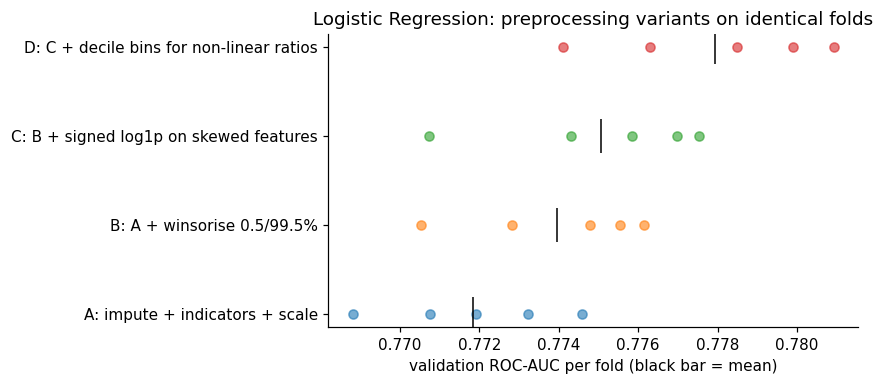

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for i, (name, g) in enumerate(cv.groupby("variant")):
    ax.scatter(g.roc_auc, [i] * len(g), alpha=.6)
    ax.plot(g.roc_auc.mean(), i, marker="|", ms=22, c="black")
ax.set_yticks(range(len(variants)), sorted(variants))
ax.set(xlabel="validation ROC-AUC per fold (black bar = mean)",
       title="Logistic Regression: preprocessing variants on identical folds")
plt.tight_layout(); fig.savefig(FIG / "04_lr_preprocessing_variants.png", bbox_inches="tight"); plt.show()

In [10]:
# Tree pipeline: functional check on fold 0 with library defaults (NOT tuned; model comparison is Step 8-9)
t = time.time()
hgb = Pipeline([("prep", tree_preprocessor(cols)),
                ("hgb", HistGradientBoostingClassifier(categorical_features=tree_categorical_mask(cols),
                                                       random_state=SEED))])
hgb.fit(dev.iloc[tr_idx], y_dev[tr_idx])
p = hgb.predict_proba(dev.iloc[va_idx])[:, 1]
print(f"HistGradientBoosting (defaults) fold 0: ROC-AUC {roc_auc_score(y_dev[va_idx], p):.4f} | "
      f"PR-AUC {average_precision_score(y_dev[va_idx], p):.4f} | inputs {len(cols['continuous']) + len(cols['binary']) + len(cols['categorical'])} "
      f"| boosting iterations {hgb[-1].n_iter_} | {time.time() - t:.0f}s")

HistGradientBoosting (defaults) fold 0: ROC-AUC 0.7762 | PR-AUC 0.2620 | inputs 181 | boosting iterations 100 | 30s


### 12.3 Logistic Regression preprocessing: evidence
The same reference model (L2, C = 1, no class weighting) was fitted on identical folds with four preprocessing variants:
* **Every added step improves validation ROC-AUC on all five folds.** Winsorising adds 0.0021, the log transform brings the
  cumulative gain to 0.0032, and decile bins for the non-linear ratios to 0.0061 (0.7719 → 0.7779).
* **Probability metrics improve too.** PR-AUC goes from 0.2553 to 0.2654, log loss from 0.2425 to 0.2403, and Brier score from 0.0671 to 0.0666.
* **The gains are real.** Each step's gain is about the size of the fold-to-fold spread (0.0022–0.0028), but it shows up
  in every fold of a paired comparison, so it is not noise. The step-3 EDA predicted it: the binned features are exactly those with
  non-linear risk curves.
* **The cost is small.** Variant D adds 46 one-hot inputs (363 → 409) and about 6 seconds per fit.

**Decision.** Variant D is the default Logistic Regression preprocessing. These results hold for this reference model; the
comparison is re-checked after regularisation and imbalance handling are tuned (Steps 7–8). D is not claimed to be optimal
for every hyperparameter setting.

### 12.4 Tree pipeline check
The gradient-boosting pipeline runs end to end, using native missing-value handling and native categorical splits.
With untouched library defaults it reaches fold-0 ROC-AUC 0.7762 using 181 inputs in 30 seconds. It stopped at the default
cap of 100 boosting iterations, which suggests room for tuning (Step 8). This is a functional check only, **not** a model
comparison: model selection uses all five folds with tuned settings in Steps 8–9.

### 12.5 Step 4 summary

| Issue | Logistic Regression | Gradient boosting | Learned from |
|---|---|---|---|
| Duplicate rows | None found (Step 2) | None found | — |
| Coded placeholders, invalid values | Set to missing in the dataset build | Same | Rules (no learning) |
| Missing values | Median imputation + missing-indicator columns | Native NaN handling | Training fold |
| Categorical variables | "Missing" category, one-hot, levels < 0.1% grouped as infrequent | Ordinal codes, native categorical splits; unseen → missing | Training fold |
| Outliers | Winsorised at the 0.5% / 99.5% quantiles; no rows removed | Not needed (trees ignore monotone rescaling) | Training fold |
| Skewed features | Signed log1p for 64 features with \|skew\| > 2 | Not needed | Development data (unsupervised) |
| Non-linear risk curves | Decile one-hot bins for 5 ratios | Learned by the trees | Training fold |
| Scaling | Standardisation | Not needed | Training fold |
| Redundancy | 17 dropped (\|ρ\| ≥ 0.95), VIF reviewed | Kept | Development data |
| Near-constant columns | 6 dropped (< 30 minority cases) | Same | Development data |
| Building triplets | AVG kept, 28 MODE/MEDI dropped | Same | EDA evidence |
| Sensitive and drift-risk columns | `CODE_GENDER`, 5 monthly-bureau and 2 bureau-annuity features excluded by default | Same | Policy / Step 2 and Step 5 evidence |

**Leakage controls.** All learned steps sit inside pipelines, a test confirms they use training-fold statistics only, and the
holdout was not used anywhere in this section.

**Stage status.** Step 4 is complete. The next stage is **Step 5 — feature engineering review**: formulas, risk relationships and
added value of the history features.